In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras import regularizers,models
from keras.layers import Flatten,Dense,Dropout
from keras.initializers import GlorotNormal,HeNormal

In [29]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()
x_train,x_test=x_train/255.0,x_test/255.0

In [30]:
#base model
bm=models.Sequential()
bm.add(Flatten(input_shape=(32,32,3)))
bm.add(Dense(256,activation='relu'))
bm.add(Dense(128,activation='relu'))
bm.add(Dense(10,activation='softmax'))

In [31]:
#xavier model
x=models.Sequential()
x.add(Flatten(input_shape=(32,32,3)))
x.add(Dense(256,activation='relu',kernel_initializer=GlorotNormal()))
x.add(Dense(128,activation='relu',kernel_initializer=GlorotNormal()))
x.add(Dense(10,activation='softmax'))

In [32]:
#kaiming model
k=models.Sequential()
k.add(Flatten(input_shape=(32,32,3)))
k.add(Dense(256,activation='relu',kernel_initializer=GlorotNormal()))
k.add(Dense(128,activation='relu',kernel_initializer=GlorotNormal()))
k.add(Dense(10,activation='softmax'))

In [33]:
#dropout model
do=models.Sequential()
do.add(Flatten(input_shape=(32,32,3)))
do.add(Dense(256,activation='relu'))
do.add(Dropout(0.5))
do.add(Dense(128,activation='relu'))
do.add(Dropout(0.5))
do.add(Dense(10,activation='softmax'))

In [34]:
#l1 regularization model
l1=models.Sequential()
l1.add(Flatten(input_shape=(32,32,3)))
l1.add(Dense(256,activation='relu',kernel_regularizer=regularizers.L1(0.01)))
l1.add(Dense(128,activation='relu',kernel_regularizer=regularizers.L1(0.01)))
l1.add(Dense(10,activation='softmax'))

#l1 regularization model
l2=models.Sequential()
l2.add(Flatten(input_shape=(32,32,3)))
l2.add(Dense(256,activation='relu',kernel_regularizer=regularizers.L2(0.01)))
l2.add(Dense(128,activation='relu',kernel_regularizer=regularizers.L2(0.01)))
l2.add(Dense(10,activation='softmax'))

In [37]:
bm.compile(optimizer='Adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
x.compile(optimizer='Adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
k.compile(optimizer='Adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
do.compile(optimizer='Adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
l1.compile(optimizer='Adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
l2.compile(optimizer='Adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [39]:
bm_his=bm.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))
x_his=x.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))
k_his=k.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))
do_his=do.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))
l1_his=l1.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))
l2_his=l2.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.4042 - loss: 1.6559 - val_accuracy: 0.4014 - val_loss: 1.6588
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.4249 - loss: 1.5945 - val_accuracy: 0.4461 - val_loss: 1.5573
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 32s 20ms/step - accuracy: 0.4481 - loss: 1.5407 - val_accuracy: 0.4382 - val_loss: 1.5577
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 37s 18ms/step - accuracy: 0.4561 - loss: 1.5127 - val_accuracy: 0.4660 - val_loss: 1.4886
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.4717 - loss: 1.4733 - val_accuracy: 0.4677 - val_loss: 1.4987
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 34s 20ms/step - accuracy: 0.2813 - loss: 1.9909 - val_accuracy: 0.3631 - val_loss: 1.7555
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 19ms/step - accuracy: 0.3839 - loss: 1.7091 - val_accuracy: 0.4203 - val_loss: 1.6256
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 31s 20ms/step - accuracy: 0.4218 - loss: 1

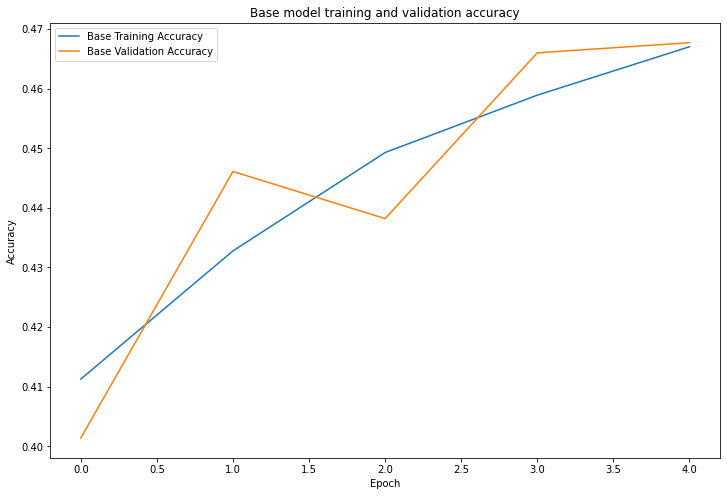

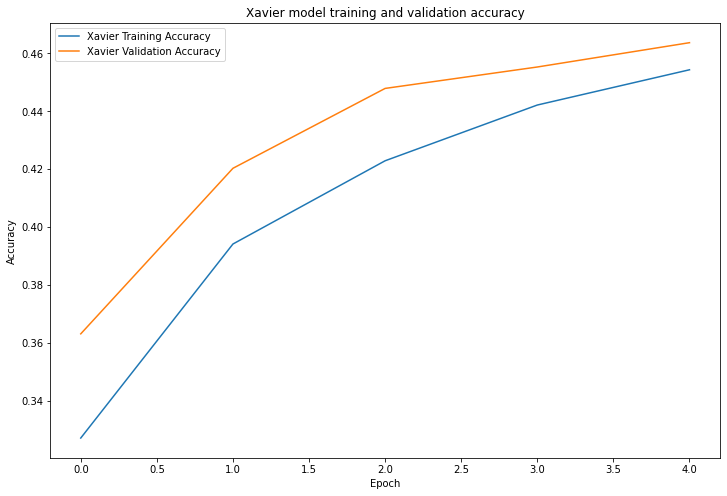

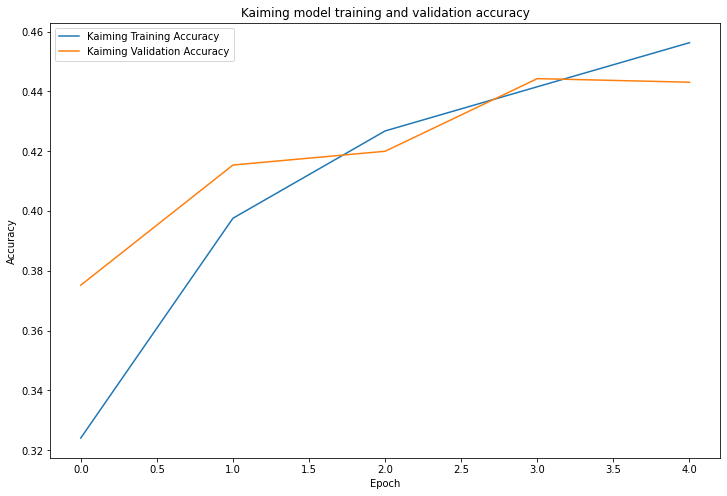

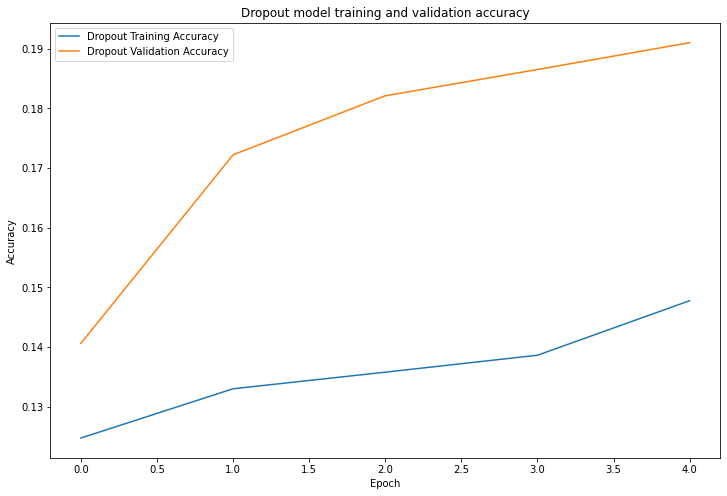

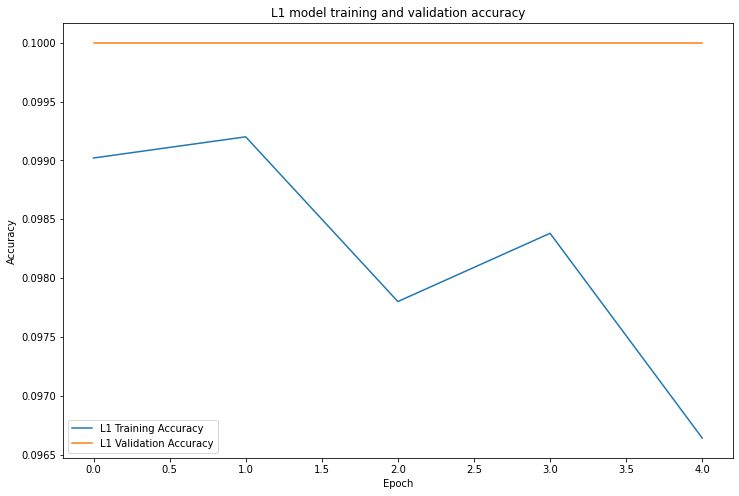

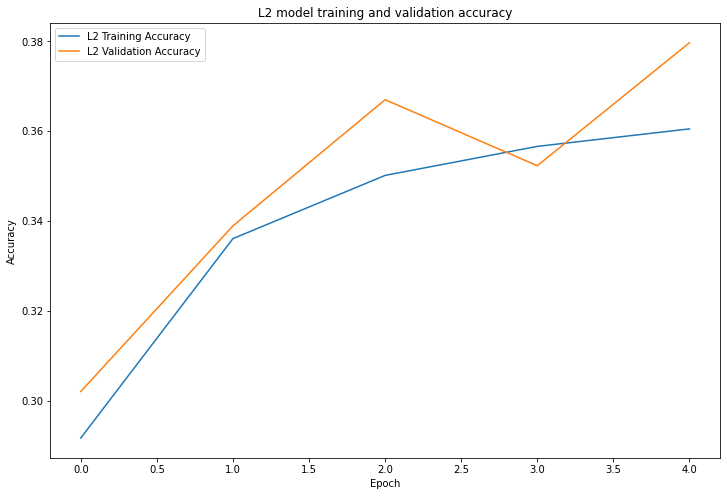

In [41]:
# 1. Base Model Accuracy
plt.figure(figsize=(12, 8))
plt.plot(bm_his.history['accuracy'], label='Base Training Accuracy')
plt.plot(bm_his.history['val_accuracy'], label='Base Validation Accuracy')
plt.title('Base model training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 2. Xavier Model Accuracy
plt.figure(figsize=(12, 8))
plt.plot(x_his.history['accuracy'], label='Xavier Training Accuracy')
plt.plot(x_his.history['val_accuracy'], label='Xavier Validation Accuracy')
plt.title('Xavier model training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 3. Kaiming Model Accuracy
plt.figure(figsize=(12, 8))
plt.plot(k_his.history['accuracy'], label='Kaiming Training Accuracy')
plt.plot(k_his.history['val_accuracy'], label='Kaiming Validation Accuracy')
plt.title('Kaiming model training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 4. Dropout Model Accuracy
plt.figure(figsize=(12, 8))
plt.plot(do_his.history['accuracy'], label='Dropout Training Accuracy')
plt.plot(do_his.history['val_accuracy'], label='Dropout Validation Accuracy')
plt.title('Dropout model training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 5. L1 Regularization Model Accuracy
plt.figure(figsize=(12, 8))
plt.plot(l1_his.history['accuracy'], label='L1 Training Accuracy')
plt.plot(l1_his.history['val_accuracy'], label='L1 Validation Accuracy')
plt.title('L1 model training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 6. L2 Regularization Model Accuracy
plt.figure(figsize=(12, 8))
plt.plot(l2_his.history['accuracy'], label='L2 Training Accuracy')
plt.plot(l2_his.history['val_accuracy'], label='L2 Validation Accuracy')
plt.title('L2 model training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


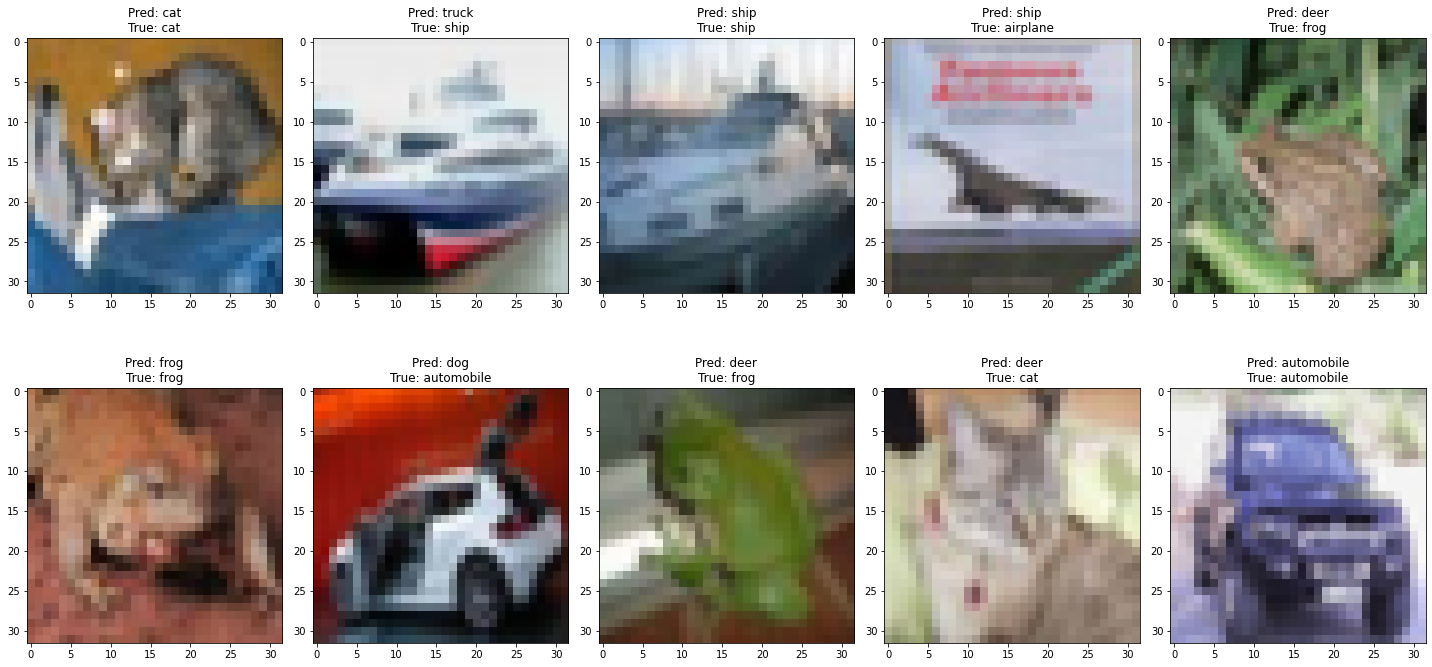

In [40]:
# Predict using the base model
base_pred = bm.predict(x_test)

# CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Display 10 test images
plt.figure(figsize=(20,10))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i])

    # Get predicted and actual class
    pred_label = np.argmax(base_pred[i])
    true_label = y_test[i][0]

    # Display predicted and actual labels
    plt.title(f'Pred: {class_names[pred_label]}\n'
              f'True: {class_names[true_label]}')

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


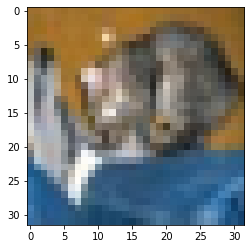

Predicted: 3
Actual: 3


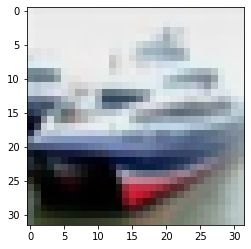

Predicted: 9
Actual: 8


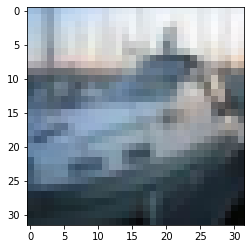

Predicted: 8
Actual: 8


In [42]:
base_pred = bm.predict(x_test).argmax(axis=1)

# Image 1
plt.imshow(x_test[0])
plt.show()
print("Predicted:", base_pred[0])
print("Actual:", y_test[0][0])

# Image 2
plt.imshow(x_test[1])
plt.show()
print("Predicted:", base_pred[1])
print("Actual:", y_test[1][0])

# Image 3
plt.imshow(x_test[2])
plt.show()
print("Predicted:", base_pred[2])
print("Actual:", y_test[2][0])